# Visualize heatmap models

Pick any architecture from `ARCH_REGISTRY` (RGB CNN, frame-diff CNN, event-frame CNN, …).
Loads the matching val batch + checkpoint, shows a modality-aware preview + GT / pred heatmaps + overlay.

New models work automatically once registered in `horus.eval.bench.ARCH_REGISTRY` with a `checkpoints/<arch>.pt` file.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from horus.config import load_config, repo_root
from horus.data.dataset import build_dataloader
from horus.eval import ARCH_REGISTRY, load_model
from horus.eval.metrics import input_channels
from horus.models import heatmap_to_coords

# --- pick a model (any key in ARCH_REGISTRY) ---
ARCH = "event_frame_cnn"  # rgb_cnn | diff_cnn | event_frame_cnn | …
SPLIT = "val"
BATCH_SIZE = 4

ROOT = repo_root()
cfg = load_config()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if ARCH not in ARCH_REGISTRY:
    raise KeyError(f"Unknown ARCH={ARCH!r}. Known: {sorted(ARCH_REGISTRY)}")
_, modality = ARCH_REGISTRY[ARCH]
ckpt_path = ROOT / "checkpoints" / f"{ARCH}.pt"
if not ckpt_path.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

model = load_model(ARCH, ckpt_path, device)
ckpt_meta = torch.load(ckpt_path, map_location="cpu", weights_only=True)
print(
    f"arch={ARCH} modality={modality} in_ch={input_channels(modality, cfg)} "
    f"epoch={ckpt_meta.get('epoch')} val_px={ckpt_meta.get('val_px')} device={device}"
)
print(f"registered: {sorted(ARCH_REGISTRY)}")

loader = build_dataloader(
    cfg, SPLIT, modality, batch_size=BATCH_SIZE, num_workers=0, shuffle=False
)
batch = next(iter(loader))
with torch.no_grad():
    pred = model(batch["input"].to(device)).cpu()
gt, coords = batch["heatmap"], batch["coords"]
pred_xy = heatmap_to_coords(pred)

arch=event_frame_cnn modality=event_frame in_ch=6 epoch=12 val_px=19.25740065578194 device=cuda
registered: ['diff_cnn', 'event_frame_cnn', 'rgb_cnn']


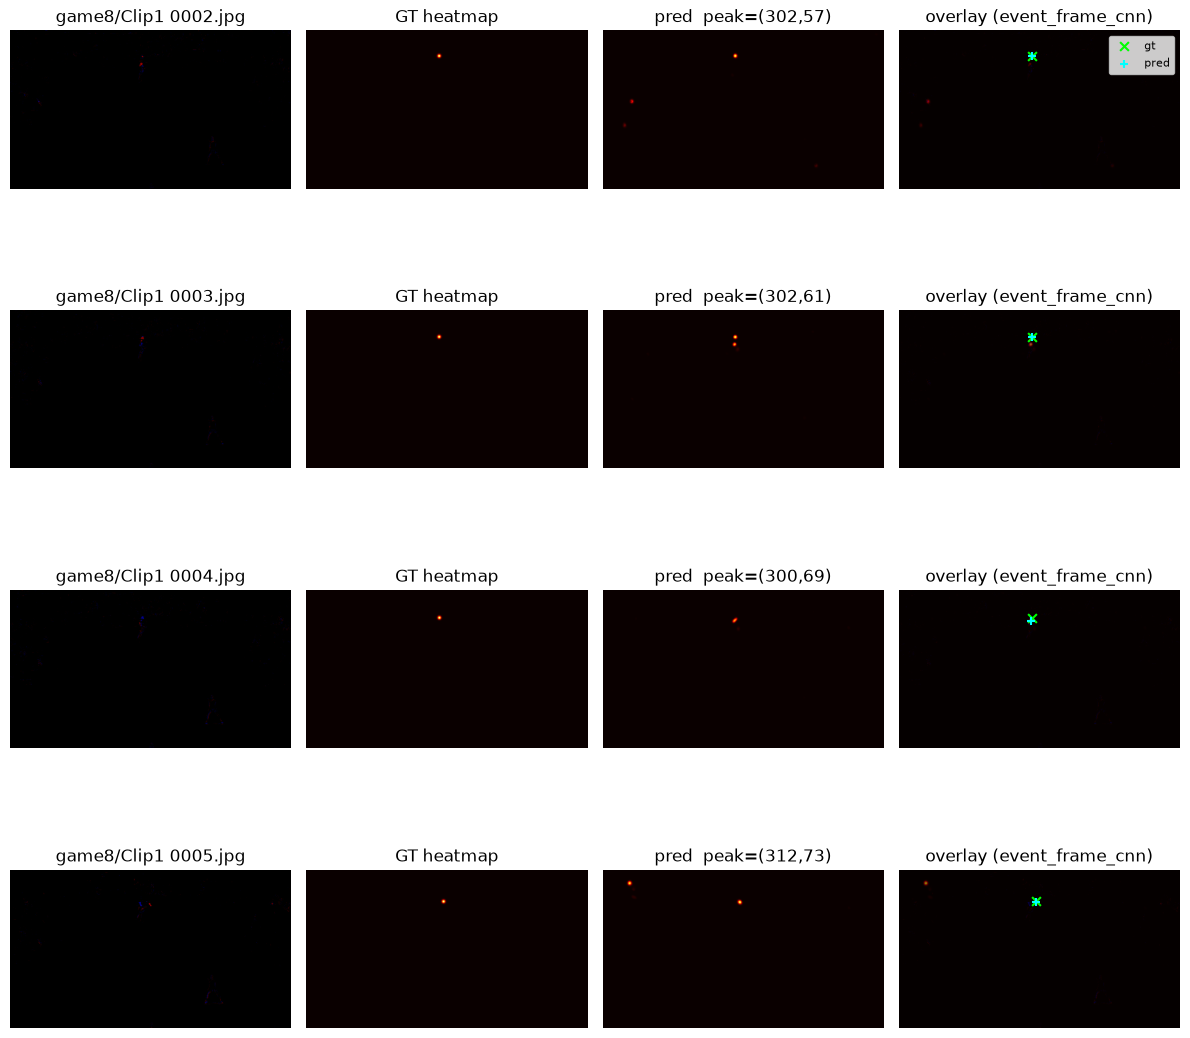

In [6]:
def preview_input(chw: torch.Tensor, modality: str, cfg: dict) -> np.ndarray:
    """Turn a stacked model input (C, H, W) into an HxWx3 float image for imshow.

    Uses the *last* frame / window slice so GT labels align with the preview.
    Extends to new modalities by adding a branch; arches that share a modality
    (e.g. future event-frame SNN) need no notebook change.
    """
    x = chw.detach().float().cpu().numpy()
    _, h, w = x.shape

    if modality == "rgb":
        # (3N, H, W) → last RGB frame
        frame = x[-3:].transpose(1, 2, 0)
        return np.clip(frame, 0, 1)

    if modality == "diff":
        # (N-1, H, W) → last abs-diff as gray
        g = x[-1]
        g = g / (g.max() + 1e-8)
        return np.stack([g, g, g], axis=-1)

    if modality == "event_frame":
        # (2N, H, W) polarity pairs → last frame as R=pos, B=neg
        pos, neg = x[-2], x[-1]
        scale = max(float(pos.max()), float(neg.max()), 1e-8)
        rgb = np.zeros((h, w, 3), dtype=np.float32)
        rgb[..., 0] = pos / scale
        rgb[..., 2] = neg / scale
        return np.clip(rgb, 0, 1)

    if modality == "voxel":
        bins = int(cfg.get("events", {}).get("voxel", {}).get("num_bins", 5))
        last = x[-bins:]  # (bins, H, W)
        g = np.abs(last).sum(axis=0)
        g = g / (g.max() + 1e-8)
        return np.stack([g, g, g], axis=-1)

    # Fallback for unknown future modalities: mean across channels
    g = np.abs(x).mean(axis=0)
    g = g / (g.max() + 1e-8)
    return np.stack([g, g, g], axis=-1)


n = pred.shape[0]
fig, axes = plt.subplots(n, 4, figsize=(12, 3 * n))
if n == 1:
    axes = axes[None, :]

for i in range(n):
    frame = preview_input(batch["input"][i], modality, cfg)
    g, p = gt[i, 0].numpy(), pred[i, 0].numpy()
    gx, gy = coords[i].tolist()
    px, py = pred_xy[i].tolist()

    axes[i, 0].imshow(frame)
    axes[i, 0].set_title(f"{batch['game'][i]}/{batch['clip'][i]} {batch['frame'][i]}")
    axes[i, 1].imshow(g, cmap="hot", vmin=0, vmax=1)
    axes[i, 1].set_title("GT heatmap")
    axes[i, 2].imshow(p, cmap="hot", vmin=0, vmax=1)
    axes[i, 2].set_title(f"pred  peak=({px:.0f},{py:.0f})")
    axes[i, 3].imshow(frame)
    axes[i, 3].imshow(p, cmap="hot", alpha=0.55, vmin=0, vmax=1)
    axes[i, 3].scatter([gx], [gy], c="lime", s=40, marker="x", label="gt")
    axes[i, 3].scatter([px], [py], c="cyan", s=40, marker="+", label="pred")
    axes[i, 3].set_title(f"overlay ({ARCH})")
    if i == 0:
        axes[i, 3].legend(loc="upper right", fontsize=8)

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()